                 country  income  life_expec  Cluster
0            Afghanistan    1610        56.2        2
1                Albania    9930        76.3        0
2                Algeria   12900        76.5        0
3                 Angola    5900        60.1        2
4    Antigua and Barbuda   19100        76.8        0
..                   ...     ...         ...      ...
162              Vanuatu    2950        63.0        2
163            Venezuela   16500        75.4        0
164              Vietnam    4490        73.1        0
165                Yemen    4480        67.5        0
166               Zambia    3280        52.0        2

[167 rows x 4 columns]


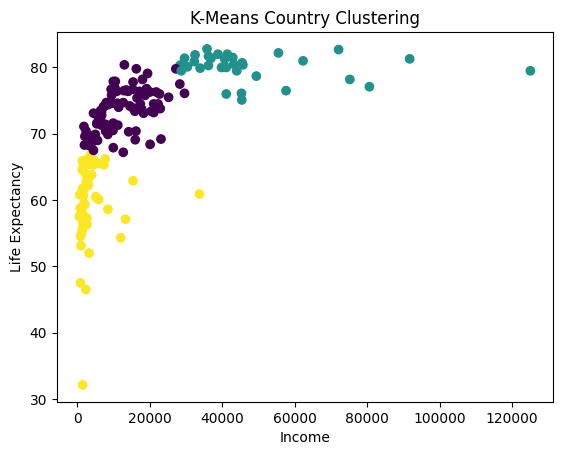

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Step 1: Load dataset
data = pd.read_csv("Country-data.csv")

# Step 2: Select two features
X = data[["income", "life_expec"]]

# Step 3: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Create 3 clusters
model = KMeans(n_clusters=3, random_state=42, n_init=10)

# Step 5: Calculate distances and assign clusters
data["Cluster"] = model.fit_predict(X_scaled)

# Step 6: Display country and cluster
print(data[["country", "income", "life_expec", "Cluster"]])

# Step 7: Plot clusters
plt.scatter(X["income"], X["life_expec"],
            c=data["Cluster"], cmap="viridis")

plt.xlabel("Income")
plt.ylabel("Life Expectancy")
plt.title("K-Means Country Clustering")
plt.show()

                 country  income  life_expec  Cluster
0            Afghanistan    1610        56.2        1
1                Albania    9930        76.3        0
2                Algeria   12900        76.5        0
3                 Angola    5900        60.1        1
4    Antigua and Barbuda   19100        76.8        0
..                   ...     ...         ...      ...
162              Vanuatu    2950        63.0        1
163            Venezuela   16500        75.4        0
164              Vietnam    4490        73.1        0
165                Yemen    4480        67.5        0
166               Zambia    3280        52.0        1

[167 rows x 4 columns]


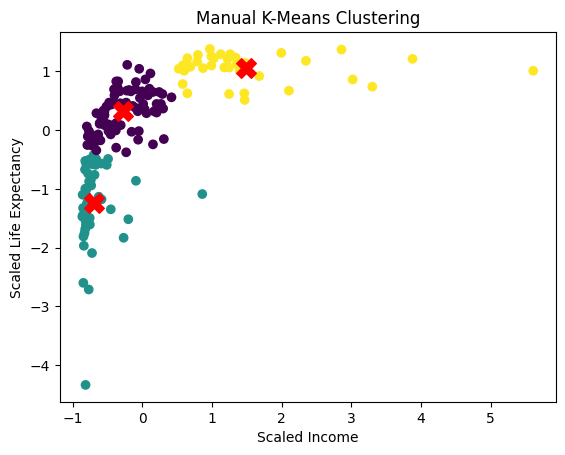

                 country  income  life_expec  Cluster
0            Afghanistan    1610        56.2        1
1                Albania    9930        76.3        0
2                Algeria   12900        76.5        0
3                 Angola    5900        60.1        1
4    Antigua and Barbuda   19100        76.8        0
..                   ...     ...         ...      ...
162              Vanuatu    2950        63.0        1
163            Venezuela   16500        75.4        0
164              Vietnam    4490        73.1        0
165                Yemen    4480        67.5        0
166               Zambia    3280        52.0        1

[167 rows x 4 columns]


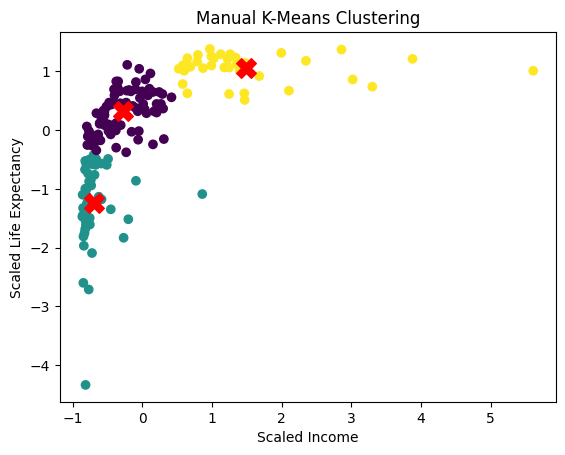

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np

# Step 1: Load dataset
data = pd.read_csv("Country-data.csv")

# Step 2: Select features
X = data[["income", "life_expec"]].values

# Step 3: Scale features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Step 4: Initialize 3 centroids
np.random.seed(42)
centroids = X[np.random.choice(len(X), 3, replace=False)]

# Step 5: Repeat K-Means
for i in range(100):

    # Calculate distance from each point to each centroid
    distances = np.linalg.norm(X[:, None] - centroids, axis=2)

    # Assign each country to nearest centroid
    labels = np.argmin(distances, axis=1)

    # Calculate new centroids
    new_centroids = np.array([
        X[labels == k].mean(axis=0) if np.any(labels == k)
        else centroids[k]
        for k in range(3)
    ])

    # Stop if centroids do not change
    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids

# Step 6: Display cluster results
data["Cluster"] = labels
print(data[["country", "income", "life_expec", "Cluster"]])

# Step 7: Plot clusters
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(centroids[:, 0], centroids[:, 1],
            color="red", marker="X", s=200)
plt.xlabel("Scaled Income")
plt.ylabel("Scaled Life Expectancy")
plt.title("Manual K-Means Clustering")
plt.show()
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np

# Step 1: Load dataset
data = pd.read_csv("Country-data.csv")

# Step 2: Select features
X = data[["income", "life_expec"]].values

# Step 3: Scale features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Step 4: Initialize 3 centroids
np.random.seed(42)
centroids = X[np.random.choice(len(X), 3, replace=False)]

# Step 5: Repeat K-Means
for i in range(100):

    # Calculate distance from each point to each centroid
    distances = np.linalg.norm(X[:, None] - centroids, axis=2)

    # Assign each country to nearest centroid
    labels = np.argmin(distances, axis=1)

    # Calculate new centroids
    new_centroids = np.array([
        X[labels == k].mean(axis=0) if np.any(labels == k)
        else centroids[k]
        for k in range(3)
    ])

    # Stop if centroids do not change
    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids

# Step 6: Display cluster results
data["Cluster"] = labels
print(data[["country", "income", "life_expec", "Cluster"]])

# Step 7: Plot clusters
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(centroids[:, 0], centroids[:, 1],
            color="red", marker="X", s=200)
plt.xlabel("Scaled Income")
plt.ylabel("Scaled Life Expectancy")
plt.title("Manual K-Means Clustering")
plt.show()

                 country  income  life_expec  Cluster
0            Afghanistan    1610        56.2        1
1                Albania    9930        76.3        0
2                Algeria   12900        76.5        0
3                 Angola    5900        60.1        1
4    Antigua and Barbuda   19100        76.8        0
..                   ...     ...         ...      ...
162              Vanuatu    2950        63.0        1
163            Venezuela   16500        75.4        0
164              Vietnam    4490        73.1        0
165                Yemen    4480        67.5        0
166               Zambia    3280        52.0        1

[167 rows x 4 columns]


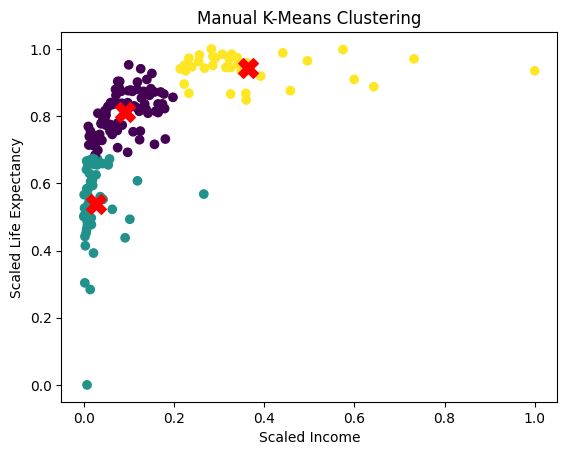

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load dataset
data = pd.read_csv("Country-data.csv")
X = data[["income", "life_expec"]].values

# 2. Scale data manually (Min-Max scaling)
minimum = X.min(axis=0)
maximum = X.max(axis=0)
X = (X - minimum) / (maximum - minimum)

# 3. Initialize 3 centroids
np.random.seed(42)
centroids = X[np.random.choice(len(X), 3, replace=False)]

# 4. Apply K-Means manually
for i in range(100):

    # Calculate distances
    distances = np.sqrt(((X[:, None] - centroids) ** 2).sum(axis=2))

    # Assign nearest cluster
    labels = np.argmin(distances, axis=1)

    # Calculate new centroids manually
    new_centroids = centroids.copy()

    for k in range(3):
        points = X[labels == k]
        if len(points) > 0:
            new_centroids[k] = points.sum(axis=0) / len(points)

    # Stop if centroids do not change
    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids

# 5. Display clusters
data["Cluster"] = labels
print(data[["country", "income", "life_expec", "Cluster"]])

# 6. Plot clusters
plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.scatter(centroids[:, 0], centroids[:, 1],
            color="red", marker="X", s=200)
plt.xlabel("Scaled Income")
plt.ylabel("Scaled Life Expectancy")
plt.title("Manual K-Means Clustering")
plt.show()

# 7. Check a new country
income = float(input("Enter income: "))
life = float(input("Enter life expectancy: "))

new_point = np.array([
    (income - minimum[0]) / (maximum[0] - minimum[0]),
    (life - minimum[1]) / (maximum[1] - minimum[1])
])

distances = np.sqrt(((centroids - new_point) ** 2).sum(axis=1))
cluster = np.argmin(distances)

print("New country belongs to Cluster:", cluster)